# Laboratory 7 - Convolutional Neural Network (CNN) Architecture & Layers

**Course:** Introduction to Artificial Intelligence (AI-101L) · **Instructor:** Dr. Muhammad Awais

---

## Learning Objectives

1. Understand how a computer represents an image as a 2D grid of pixel numbers (grayscale) or 3D tensor (RGB channels).
2. Implement the **2D Convolution (`Conv2D`)** operation from scratch using a $3\times3$ sliding kernel and verify the output dimension formula $O = \lfloor \frac{I - K + 2P}{S} \rfloor + 1$.
3. Apply the **ReLU Activation Function** $f(x) = \max(0, x)$ to introduce non-linearity.
4. Apply **Max Pooling (`MaxPooling2D`)** to downsample feature maps, reduce computation, and achieve translation invariance.
5. Flatten the 2D pooled map into a 1D vector, compute **Fully Connected (`Dense`)** logits $z = \mathbf{w}\cdot\mathbf{x} + b$, and convert logits into class probabilities using **Softmax** $\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$.

In [1]:
# Stage 1: Define the 5x5 Grayscale Input Image and 3x3 Convolution Kernel (from CNN Architecture.pptx)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

input_image = np.array([
    [3, 1, 0, 2, 1],
    [2, 0, 1, 3, 0],
    [4, 1, 0, 1, 2],
    [1, 3, 2, 0, 1],
    [0, 2, 1, 4, 2]
])

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

print("Input Image Shape:", input_image.shape)
print(input_image)
print("\n3x3 Vertical Edge Kernel Shape:", kernel.shape)
print(kernel)

Input Image Shape: (5, 5)
[[3 1 0 2 1]
 [2 0 1 3 0]
 [4 1 0 1 2]
 [1 3 2 0 1]
 [0 2 1 4 2]]

3x3 Vertical Edge Kernel Shape: (3, 3)
[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


In [2]:
# Stage 2: 2D Convolution Layer (Sliding 3x3 Kernel, Stride=1, Padding=0)
def conv2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image = np.pad(image, pad_width=padding, mode="constant", constant_values=0)
    H, W = image.shape
    kH, kW = kernel.shape
    out_H = (H - kH) // stride + 1
    out_W = (W - kW) // stride + 1
    feature_map = np.zeros((out_H, out_W), dtype=int)
    for i in range(out_H):
        for j in range(out_W):
            patch = image[i*stride:i*stride+kH, j*stride:j*stride+kW]
            feature_map[i, j] = np.sum(patch * kernel)
    return feature_map

feature_map = conv2d(input_image, kernel, stride=1, padding=0)
print("Top-left patch calculation: 3*1 + 1*0 + 0*(-1) + 2*1 + 0*0 + 1*(-1) + 4*1 + 1*0 + 0*(-1) =", feature_map[0, 0])
print("Output Feature Map Shape (5 - 3 + 1 = 3x3):", feature_map.shape)
print(feature_map)

Top-left patch calculation: 3*1 + 1*0 + 0*(-1) + 2*1 + 0*0 + 1*(-1) + 4*1 + 1*0 + 0*(-1) = 8
Output Feature Map Shape (5 - 3 + 1 = 3x3): (3, 3)
[[ 8 -4 -2]
 [ 4  0  0]
 [ 2  1 -2]]


In [3]:
# Stage 3 & Stage 4: ReLU Activation f(x) = max(0, x) and 2x2 Max Pooling
relu_output = np.maximum(0, feature_map)
print("Stage 3 - After ReLU Activation (negative numbers become 0):")
print(relu_output)

def max_pooling2d(fmap, pool_size=2, stride=1):
    H, W = fmap.shape
    out_H = (H - pool_size) // stride + 1
    out_W = (W - pool_size) // stride + 1
    pooled = np.zeros((out_H, out_W), dtype=fmap.dtype)
    for i in range(out_H):
        for j in range(out_W):
            window = fmap[i*stride:i*stride+pool_size, j*stride:j*stride+pool_size]
            pooled[i, j] = np.max(window)
    return pooled

pooled_output = max_pooling2d(relu_output, pool_size=2, stride=1)
print("\nStage 4 - After 2x2 Max Pooling (keeps max value in each 2x2 window):")
print("First 2x2 window max(8, 0, 4, 0) =", pooled_output[0, 0])
print(pooled_output)

Stage 3 - After ReLU Activation (negative numbers become 0):
[[8 0 0]
 [4 0 0]
 [2 1 0]]

Stage 4 - After 2x2 Max Pooling (keeps max value in each 2x2 window):
First 2x2 window max(8, 0, 4, 0) = 8
[[8 0]
 [4 1]]


In [4]:
# Stage 5 & Stage 6: Flatten + Fully Connected Layer (Logits) + Softmax Output
flattened = pooled_output.flatten()
print("Stage 5a - Flattened 1D Vector:", flattened)

classes = ["Cat", "Dog", "Bird"]
weights = np.array([
    [0.3, 0.1, 0.2, 0.1],  # Cat weights
    [0.1, 0.2, 0.1, 0.3],  # Dog weights
    [0.0, 0.4, 0.1, 0.2],  # Bird weights
])

logits = weights @ flattened
exp_logits = np.exp(logits)
probabilities = exp_logits / np.sum(exp_logits)

summary_table = pd.DataFrame({
    "Class": classes,
    "Weights": [list(w) for w in weights],
    "Logit (z)": np.round(logits, 2),
    "exp(z)": np.round(exp_logits, 4),
    "Softmax Probability (%)": np.round(probabilities * 100, 1)
})
print("\nStage 5b & 6 - Fully Connected Logits and Softmax Probabilities:")
print(summary_table.to_string(index=False))
print(f"\nFinal Prediction: {classes[int(np.argmax(probabilities))]} ({probabilities.max()*100:.0f}%)")

Stage 5a - Flattened 1D Vector: [8 0 4 1]

Stage 5b & 6 - Fully Connected Logits and Softmax Probabilities:
Class              Weights  Logit (z)  exp(z)  Softmax Probability (%)
  Cat [0.3, 0.1, 0.2, 0.1]        3.3 27.1126                     81.1
  Dog [0.1, 0.2, 0.1, 0.3]        1.5  4.4817                     13.4
 Bird [0.0, 0.4, 0.1, 0.2]        0.6  1.8221                      5.5

Final Prediction: Cat (81%)


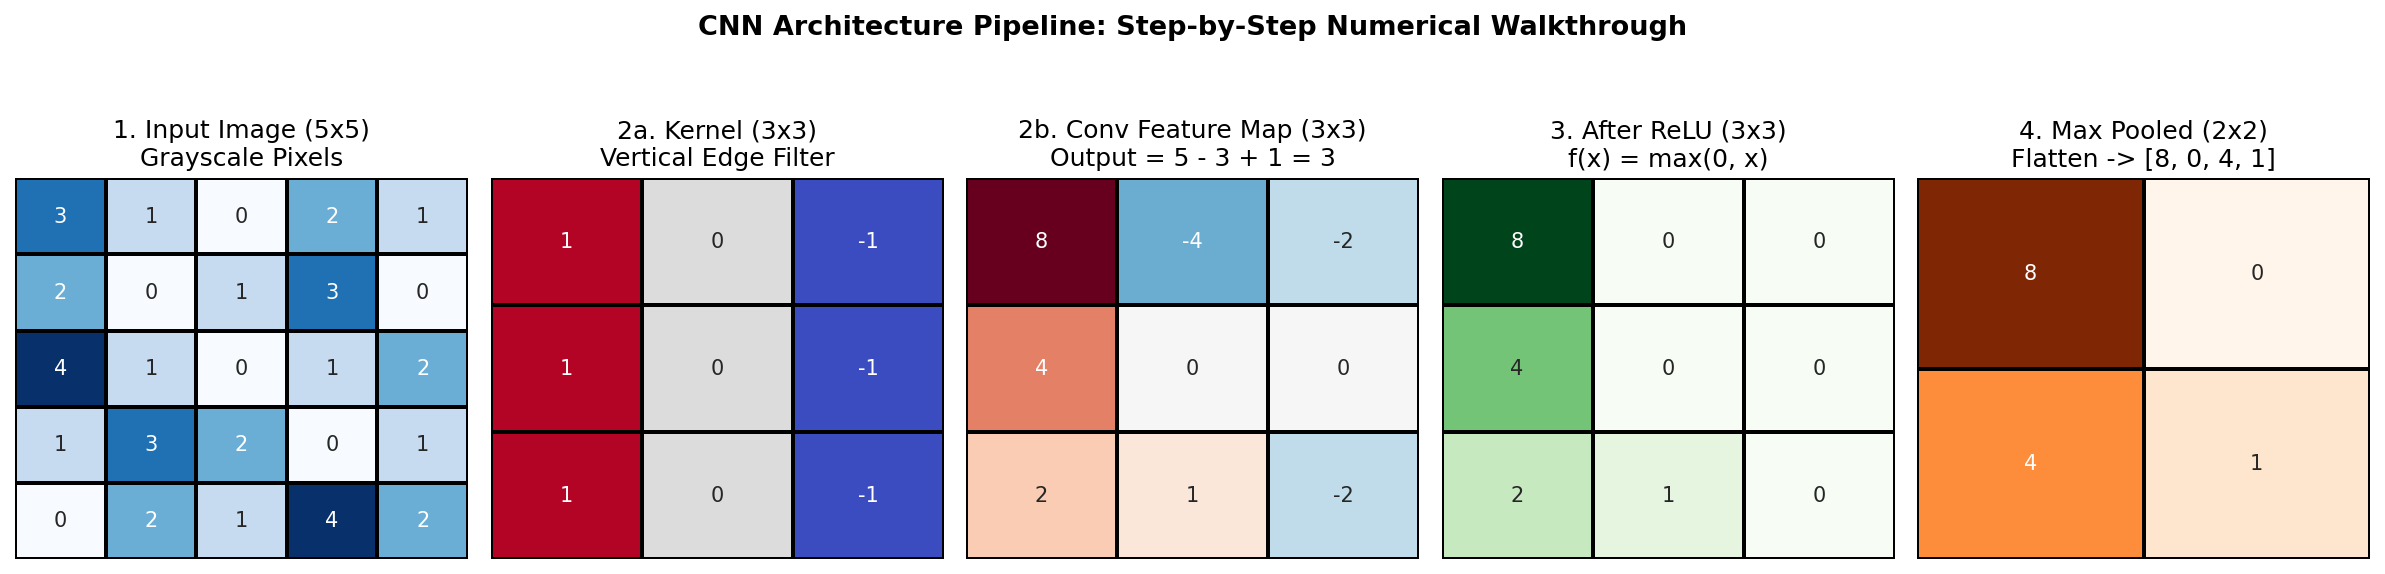

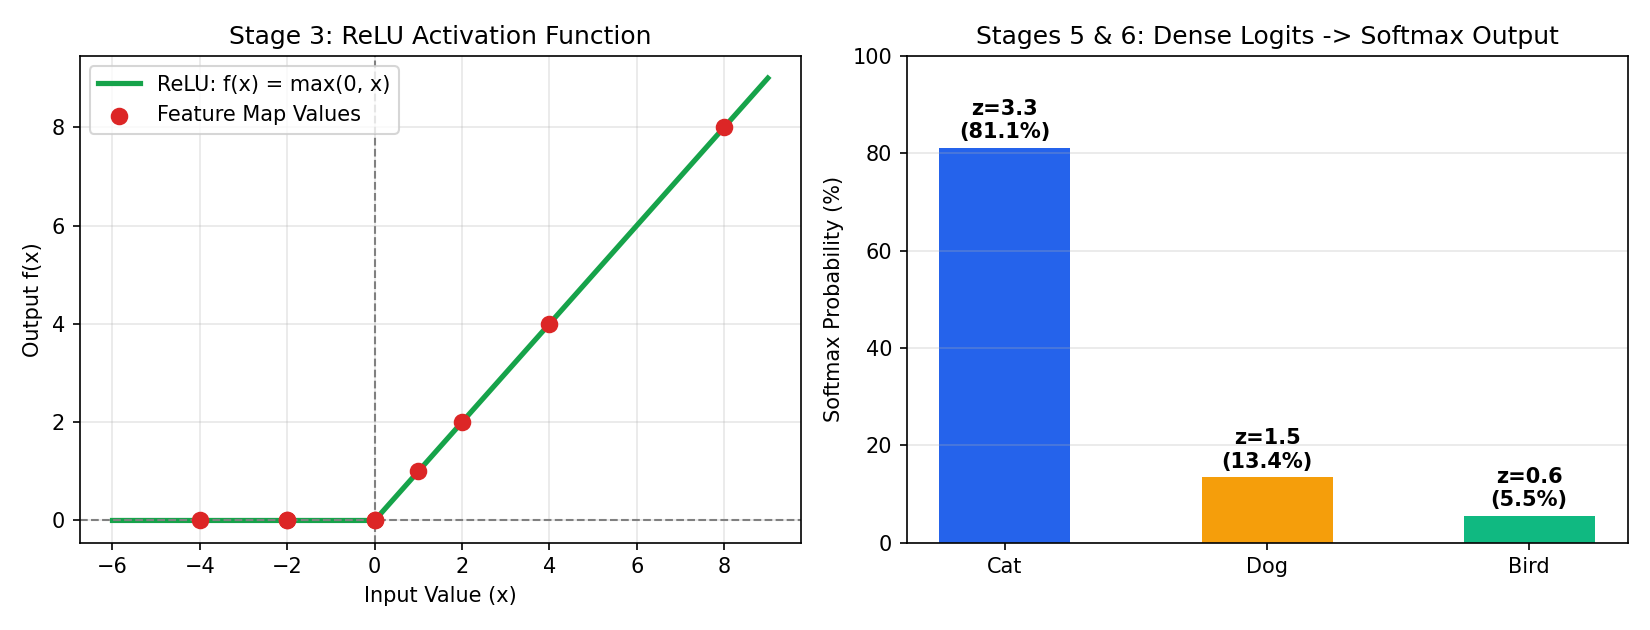

In [5]:
# Visualize all 6 stages of the CNN Architecture Pipeline
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
sns.heatmap(input_image, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], linewidths=1, linecolor="black")
axes[0].set_title("1. Input Image (5x5)")
sns.heatmap(kernel, annot=True, fmt="d", cmap="coolwarm", cbar=False, ax=axes[1], linewidths=1, linecolor="black")
axes[1].set_title("2a. Kernel (3x3)")
sns.heatmap(feature_map, annot=True, fmt="d", cmap="RdBu_r", center=0, cbar=False, ax=axes[2], linewidths=1, linecolor="black")
axes[2].set_title("2b. Conv Feature Map (3x3)")
sns.heatmap(relu_output, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[3], linewidths=1, linecolor="black")
axes[3].set_title("3. After ReLU (3x3)")
sns.heatmap(pooled_output, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[4], linewidths=1, linecolor="black")
axes[4].set_title("4. Max Pooled (2x2)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [6]:
# Exercise: Output Dimension Formula & Parameter Count Verification (Connecting Lab 07 to Lab 08 MNIST CNN)
def conv_output_size(input_size, kernel_size, padding=0, stride=1):
    return (input_size - kernel_size + 2 * padding) // stride + 1

def conv_param_count(k_h, k_w, in_channels, out_filters, use_bias=True):
    bias = 1 if use_bias else 0
    return (k_h * k_w * in_channels + bias) * out_filters

print("Slide Walkthrough Output Size (5x5 input, 3x3 kernel, P=0, S=1):", conv_output_size(5, 3, 0, 1))
print("With Same Padding (5x5 input, 3x3 kernel, P=1, S=1)           :", conv_output_size(5, 3, 1, 1))
print("MNIST Block 1 Conv2D (28x28x1 -> 32 filters of 3x3)           : Shape =", conv_output_size(28, 3, 0, 1), "| Params =", conv_param_count(3, 3, 1, 32))
print("MNIST Block 2 Conv2D (13x13x32 -> 64 filters of 3x3)          : Shape =", conv_output_size(13, 3, 0, 1), "| Params =", conv_param_count(3, 3, 32, 64))

Slide Walkthrough Output Size (5x5 input, 3x3 kernel, P=0, S=1): 3
With Same Padding (5x5 input, 3x3 kernel, P=1, S=1)           : 5
MNIST Block 1 Conv2D (28x28x1 -> 32 filters of 3x3)           : Shape = 26 | Params = 320
MNIST Block 2 Conv2D (13x13x32 -> 64 filters of 3x3)          : Shape = 11 | Params = 18496
